In [1]:
import numpy as np
import matplotlib.pyplot as plt
from SingleAgent import *

The Payoff Matrix:

| **Player A / Player B** | **Cooperate (C)** | **Defect (D)** |
|-------------------------|-------------------|----------------|
| **Cooperate (C)**       | R = 0.8           | S = 0          |
| **Defect (D)**          | T = 1.0           | P = 0.2        |

In [2]:
#correct always defecting and try to understand why Q01 and Q10 are inverted

## Theoretical Qlearning values

In [21]:
delta_value = 0.43
epsilon_value = 0.1
lambda_value = 0
P, R, T, S = 0.2, 0.8, 1, 0
#critical deltas
c2 = ((2*P) - (epsilon_value *P) - (epsilon_value *R) - (2 *S) + (epsilon_value *S) + (epsilon_value *T))/((-1 + epsilon_value) *((-2 *P) + (2 *epsilon_value *P) + (2 *S) - (epsilon_value *S) - (epsilon_value *T)))
c1 = (-epsilon_value *P + 2 *R - epsilon_value *R + epsilon_value *S - 2 *T + epsilon_value *T)/((-1 + epsilon_value)* (-2 *P + 2 *epsilon_value *P - epsilon_value *S + 2 *T - epsilon_value *T))

In [22]:
print(f'c1 is {round(c1,3)}', f'and c2 is {round(c2, 3)}')

c1 is 0.289 and c2 is 0.966


## Single Run

In [23]:
strategy = epsilon_GrimTrigger()
solver = PrisonersDilemmaSolver(
    strategy=strategy,
    e_initial=epsilon_value,
    lambda_val=lambda_value,
    alpha=0.1,
    delta=delta_value,
    K=5,
    M=10,
    e_decay=1,
    random_uniform=True,
    verbose=False
)

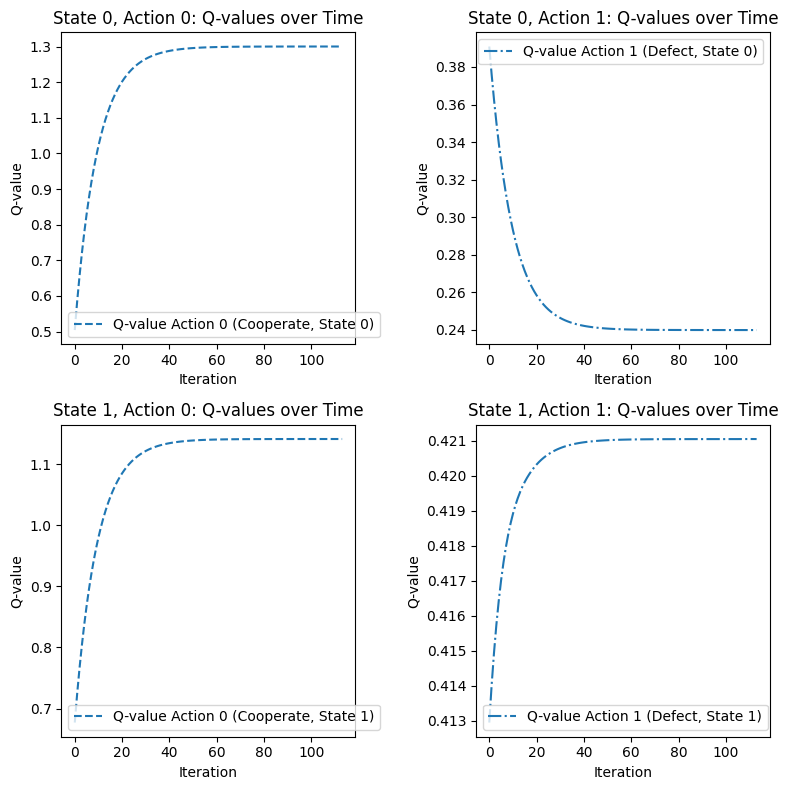

Cooperations: 1029, Defections: 78


In [24]:
# Run the solver
cooperations, defections, q1_history, mean_q_values, grim_trigger_count_dict, initial_q_value = solver.run()
# Check results
print(f"Cooperations: {cooperations}, Defections: {defections}")


### Calculate Theoretical Q-Values

In [25]:
calculator = Theoretical_QValueCalculator(epsilon=epsilon_value, P=P, R=R, T=T, S=S, delta=delta_value)
Q00, Q01, Q10, Q11 = calculator.calculate_q_values(c1, c2)


Strategy is e-Always Defecting


In [26]:
Q00, Q01, Q10, Q11

(0.8273018181818182,
 0.1258618181818182,
 0.9581818181818182,
 0.31818181818181823)

### Value Iteration Check

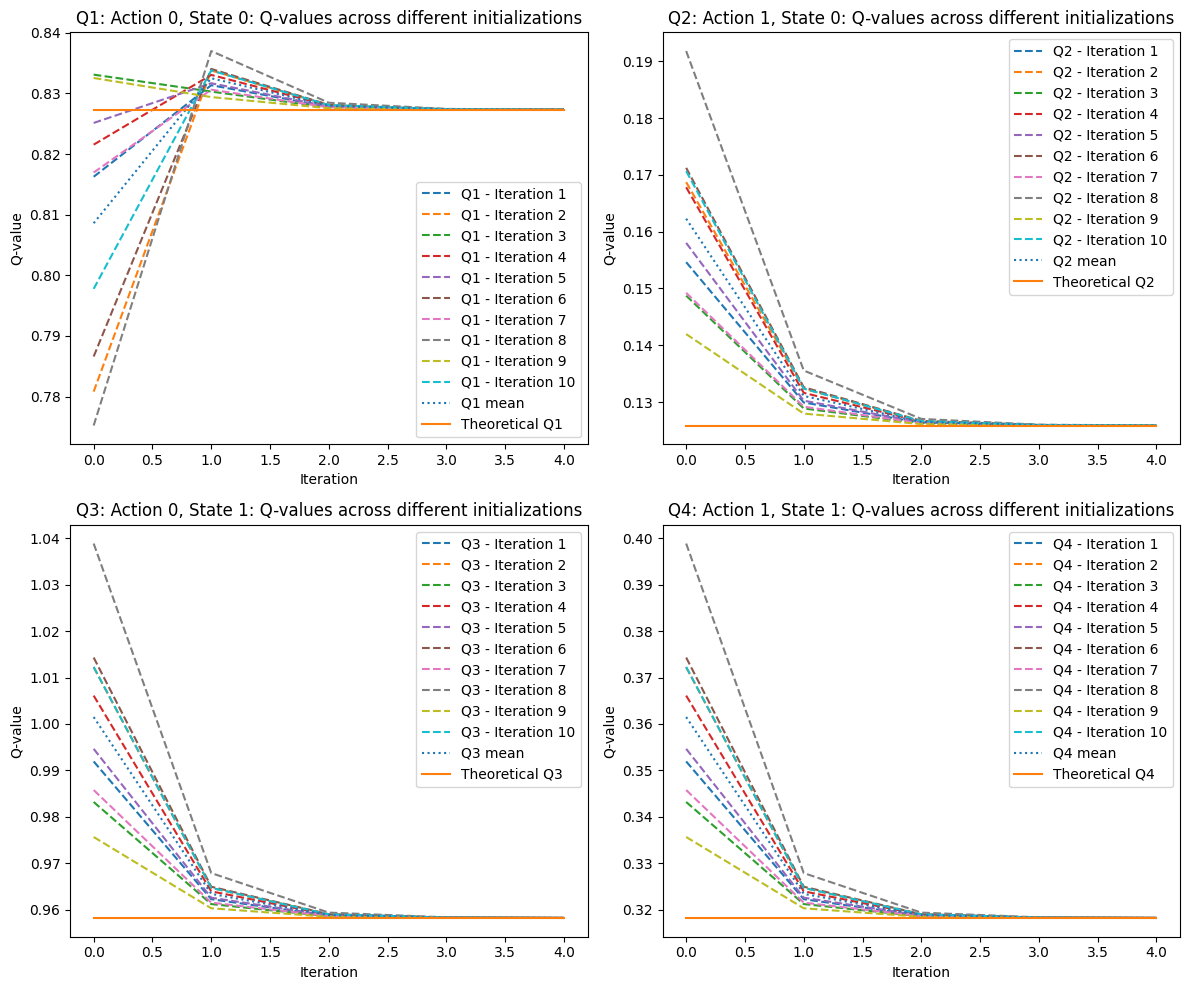

In [27]:
solver.plot_value_iteration(Q00, Q01, Q10, Q11, False)

In [28]:
break

SyntaxError: 'break' outside loop (668683560.py, line 1)

## Critical Value of delta

In [16]:
def analyze_critical_delta(delta_values, epsilon_values):
    """
    Analyzes the critical value of delta for which the agent begins cooperating against the Grim Trigger strategy.

    Parameters:
        None.

    Returns:
        A plot of cooperation ratio vs. delta.
    """
    import numpy as np
    import matplotlib.pyplot as plt

    # Define the payoffs
    P, R, T, S = 0.2, 0.8, 1, 0

    # Create a 2D grid for strategies
    strategy_grid = np.zeros((len(delta_values), len(epsilon_values)))

    # Iterate over all (delta, epsilon) pairs
    for i, delta in enumerate(delta_values):
        for j, epsilon in enumerate(epsilon_values):
            if epsilon == 1:  # Avoid division by zero when epsilon is 1
                strategy_grid[i, j] = 0
                continue
            # Example calculation (replace this with actual logic)
            calculator = Theoretical_QValueCalculator(epsilon=epsilon, P=P, R=R, T=T, S=S, delta=delta)
            c1, c2 = calculator.calculate_c1_c2()
            strategy = calculator.print_strategy_chosen(c1, c2)
            strategy_grid[i, j] = strategy

    # Debug: Ensure all values are in the expected range
    strategy_grid = np.clip(strategy_grid, 1, 4)  # Clip values to ensure they are in [1, 4]
    return strategy_grid

def plot_strategy_grid(strategy_grid, delta_values, epsilon_values):
    """
    Plots the strategy grid with clear color mapping.

    Parameters:
        strategy_grid (np.ndarray): 2D array representing the strategies.
        delta_values (np.ndarray): Array of delta values.
        epsilon_values (np.ndarray): Array of epsilon values.

    Returns:
        None. Displays the plot.
    """
    import numpy as np
    import matplotlib.pyplot as plt

    # Debug: Print unique values in the strategy grid
    unique_strategies = np.unique(strategy_grid)
    print("Unique strategies in grid:", unique_strategies)

    # Define the color mapping
    levels = [0, 1, 2, 3]  # Define boundaries for strategies
    colors = ['white', 'blue', 'orange', 'green']  # Color for each strategy
    cmap = plt.matplotlib.colors.ListedColormap(colors[1:])  # Omit 'white' as it's for level 0

    # Create the mesh grid
    delta_mesh, epsilon_mesh = np.meshgrid(epsilon_values, delta_values)

    # Plotting
    plt.figure(figsize=(8, 8))
    contour = plt.contourf(delta_mesh, epsilon_mesh, strategy_grid, levels=levels, cmap=cmap, extend='both')

    # Add color bar with proper ticks and labels
    cbar = plt.colorbar(contour, ticks=[1, 2, 3])  # Adjusted ticks to match the strategy levels
    cbar.set_label('Strategy')
    cbar.ax.set_yticklabels(['AD', 'GT', 'AC'])

    # Label axes and title
    plt.xlabel(r'$\epsilon$')
    plt.ylabel(r'$\delta$')
    plt.title('Strategy Choice Based on $\delta$ and $\epsilon$')

    # Display the plot
    plt.show()



In [17]:
# Range of delta and epsilon values
delta_values = np.linspace(0, 0.999, 100)
epsilon_values = np.linspace(0, 0.99, 100)
a = analyze_critical_delta(delta_values, epsilon_values)

In [18]:
pd.DataFrame((a).reshape(1,10000).T)[0].value_counts()

0
1.0    6541
2.0    3359
3.0     100
Name: count, dtype: int64

Unique strategies in grid: [1. 2. 3.]


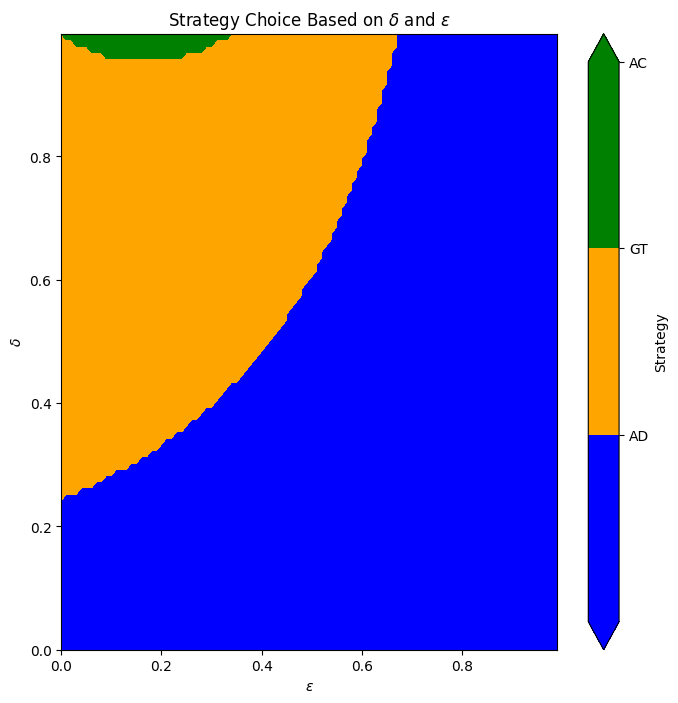

In [19]:
plot_strategy_grid(a, delta_values, epsilon_values)

In [25]:
q1_history

[array([[0.84645408, 0.30025582],
        [0.68538003, 0.15237788]]),
 array([[0.89126973, 0.2940281 ],
        [0.73076971, 0.17906777]]),
 array([[0.93165273, 0.28841705],
        [0.77161126, 0.20307952]]),
 array([[0.9680415 , 0.28336161],
        [0.80836041, 0.22468185]]),
 array([[1.0008311 , 0.27880676],
        [0.84142722, 0.24411651]]),
 array([[1.03037753, 0.27470294],
        [0.87118065, 0.26160101]]),
 array([[1.05700156, 0.27100548],
        [0.8979527 , 0.27733102]]),
 array([[1.08099434, 0.26768307],
        [0.92205141, 0.2914919 ]]),
 array([[1.10261985, 0.26471431],
        [0.94376107, 0.30425751]]),
 array([[1.12211165, 0.26206171],
        [0.96331852, 0.31576532]]),
 array([[1.13968027, 0.25969178],
        [0.98093715, 0.32613927]]),
 array([[1.15551547, 0.25757452],
        [0.99680917, 0.33549108]]),
 array([[1.16978827, 0.25568312],
        [1.01110773, 0.34392145]]),
 array([[1.18265282, 0.2539936 ],
        [1.02398883, 0.35152118]]),
 array([[1.19424809,

In [26]:
mean_q_values

,Q1,Q2,Q3,Q4
0,0.504429,0.390907,0.677227,0.412943
1,0.583834,0.376050,0.723871,0.414015
2,0.655270,0.362640,0.765811,0.414940
3,0.719542,0.350537,0.803522,0.415738
4,0.777369,0.339613,0.837430,0.416425
...,...,...,...,...
109,1.300163,0.239955,1.141049,0.421054
110,1.300163,0.239955,1.141049,0.421055
111,1.300164,0.239955,1.141049,0.421054
112,1.300164,0.239955,1.141051,0.421054
